# Notebook 03: Penemuan Data Mentah (*Data Discovery*)

Menutup `02_technical_objectives.ipynb`, kita membawa empat daftar kebutuhan data dari `reports/task_spec.md` (**DRAF**):
1. Rekaman pasif ponsel harian dengan catatan gejala klinis/EMA.
2. Data aktivitas populasi umum berskala besar untuk referensi **Kurva Sehat**.
3. Data aktigrafi pasien klinis dan kontrol sehat.
4. Kepastian total ukuran file agar aman diproses di **laptop 8 GB RAM**.

Sebelum menyusun aturan validasi atau memilih kolom, kita harus melihat sendiri isi folder penyimpanan data mentah: format file apa yang ada, berapa banyak tabelnya, dan berapa besar kebutuhan memori saat dimuat.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

with open(ROOT / "config.json", "r", encoding="utf-8") as f:
    CONFIG = json.load(f)

DATA_RAW = ROOT / CONFIG["paths"]["data_raw"]
REPORTS_DIR = ROOT / CONFIG["paths"]["reports"]
DATA_CARDS_DIR = ROOT / CONFIG["paths"]["data_cards"]
FIGURES_DIR = ROOT / CONFIG["paths"]["artifacts_figures"]

for d in (DATA_RAW, REPORTS_DIR, DATA_CARDS_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"DATA_RAW       : {DATA_RAW}")
print(f"REPORTS_DIR    : {REPORTS_DIR}")
print(f"DATA_CARDS_DIR : {DATA_CARDS_DIR}")
print(f"RAM Budget     : {CONFIG['project']['ram_budget_gb']} GB")


DATA_RAW       : ./data\raw
REPORTS_DIR    : ./reports
DATA_CARDS_DIR : ./reports\data_cards
RAM Budget     : 8 GB


Jalur penyimpanan data mentah dan target batas **RAM = 8 GB** terkonfirmasi siap dipakai untuk pemindaian.

### Langkah 1: Memindai Inventaris File, Skema Kolom, dan Anggaran Memori

Di sel berikut, kita melakukan pemindaian awal (*metadata scan*) tanpa memodifikasi satu nilai pun:
- Menghitung total ukuran file di disk dan estimasi memori jika seluruh tabel dimuat.
- Memeriksa jumlah baris, jumlah kolom, dan jumlah subjek unik di tiap sumber data.
- Secara khusus mencari apakah dataset pasif ponsel memiliki **kolom diagnosis relaps atau skala klinis BPRS eksplisit**, karena informasi ini akan menentukan bentuk variabel target kita di langkah pemodelan nanti.

In [2]:
def dir_size_mb(path: Path) -> float:
    if not path.exists():
        return 0.0
    return round(sum(p.stat().st_size for p in path.rglob("*") if p.is_file()) / (1024 ** 2), 2)


def find_subject_col(cols: list[str]) -> str | None:
    for cand in ["study_id", "pid", "uid", "subject_id", "subject", "id", "SEQN", "number"]:
        if cand in cols:
            return cand
    return None


schema_summary = {}
overview_rows = []

# 1. CrossCheck (cleaned daily CSV)
cc_path = DATA_RAW / "crosscheck" / "crosscheck_daily_data_cleaned_w_sameday.csv"
df_cc = pd.read_csv(cc_path) if cc_path.exists() else pd.DataFrame()
if not df_cc.empty:
    cc_id_col = find_subject_col(df_cc.columns.tolist())
    cc_relapse_cols = [c for c in df_cc.columns if any(k in c.lower() for k in ["relapse", "hosp", "bprs"])]
    cc_ema_cols = [c for c in df_cc.columns if "ema" in c.lower()]
    schema_summary["crosscheck_cleaned"] = {
        "rows": int(len(df_cc)),
        "cols": int(df_cc.shape[1]),
        "id_col": cc_id_col,
        "unique_subjects": int(df_cc[cc_id_col].nunique()) if cc_id_col else None,
        "relapse_or_bprs_cols": cc_relapse_cols,
        "ema_cols_sample": cc_ema_cols[:15],
        "ram_mb": round(df_cc.memory_usage(deep=True).sum() / (1024 ** 2), 2),
    }
    overview_rows.append({
        "dataset": "CrossCheck (cleaned)",
        "modalitas": "Sensor ponsel + EMA",
        "subjek_unik": schema_summary["crosscheck_cleaned"]["unique_subjects"],
        "baris": len(df_cc),
        "kolom": df_cc.shape[1],
        "missing_rata2_pct": round(float(df_cc.isna().mean().mean() * 100), 2),
        "disk_mb": dir_size_mb(DATA_RAW / "crosscheck"),
        "ram_mb": schema_summary["crosscheck_cleaned"]["ram_mb"],
    })

# 2. StudentLife (cleaned daily CSV)
sl_path = DATA_RAW / "studentlife" / "studentlife_daily_data_cleaned_w_sameday_08282021.csv"
df_sl = pd.read_csv(sl_path) if sl_path.exists() else pd.DataFrame()
if not df_sl.empty:
    sl_id_col = find_subject_col(df_sl.columns.tolist())
    sl_ema_cols = [c for c in df_sl.columns if any(k in c.lower() for k in ["ema", "stress", "sleep", "mood", "pam"])]
    schema_summary["studentlife_cleaned"] = {
        "rows": int(len(df_sl)),
        "cols": int(df_sl.shape[1]),
        "id_col": sl_id_col,
        "unique_subjects": int(df_sl[sl_id_col].nunique()) if sl_id_col else None,
        "ema_or_target_cols": sl_ema_cols[:15],
        "ram_mb": round(df_sl.memory_usage(deep=True).sum() / (1024 ** 2), 2),
    }
    overview_rows.append({
        "dataset": "StudentLife (cleaned)",
        "modalitas": "Sensor ponsel + EMA",
        "subjek_unik": schema_summary["studentlife_cleaned"]["unique_subjects"],
        "baris": len(df_sl),
        "kolom": df_sl.shape[1],
        "missing_rata2_pct": round(float(df_sl.isna().mean().mean() * 100), 2),
        "disk_mb": dir_size_mb(DATA_RAW / "studentlife"),
        "ram_mb": schema_summary["studentlife_cleaned"]["ram_mb"],
    })

# 3. NHANES 2011-2014 (DEMO_G/H + PAXDAY_G/H + PhysioNet subject-info)
nh_dir = DATA_RAW / "nhanes"
nh_info = {}
pax_frames = []
for xpt_name in ["DEMO_G.xpt", "DEMO_H.xpt", "PAXDAY_G.xpt", "PAXDAY_H.xpt"]:
    xp = nh_dir / xpt_name
    if xp.exists():
        df_x = pd.read_sas(xp, format="xport")
        nh_info[xpt_name] = {
            "rows": int(len(df_x)),
            "cols": int(df_x.shape[1]),
            "unique_seqn": int(df_x["SEQN"].nunique()) if "SEQN" in df_x.columns else None,
            "ram_mb": round(df_x.memory_usage(deep=True).sum() / (1024 ** 2), 2),
        }
        if xpt_name.startswith("PAXDAY"):
            cols_keep = [c for c in ["SEQN", "PAXWWMD", "PAXSWMD", "PAXNWMD", "PAXMTSD"] if c in df_x.columns]
            pax_frames.append(df_x[cols_keep])

df_paxday = pd.concat(pax_frames, ignore_index=True) if pax_frames else pd.DataFrame()
pn_subj_path = nh_dir / "physionet_subject-info.csv"
if pn_subj_path.exists():
    df_pn_subj = pd.read_csv(pn_subj_path)
    nh_info["physionet_subject_info"] = {
        "rows": int(len(df_pn_subj)),
        "cols": int(df_pn_subj.shape[1]),
        "columns": df_pn_subj.columns.tolist(),
    }
schema_summary["nhanes"] = nh_info
if not df_paxday.empty:
    overview_rows.append({
        "dataset": "NHANES 2011-2014 (PAXDAY)",
        "modalitas": "Wrist-actigraphy (referensi Kurva Sehat)",
        "subjek_unik": int(df_paxday["SEQN"].nunique()),
        "baris": len(df_paxday),
        "kolom": df_paxday.shape[1],
        "missing_rata2_pct": round(float(df_paxday.isna().mean().mean() * 100), 2),
        "disk_mb": dir_size_mb(nh_dir),
        "ram_mb": round(df_paxday.memory_usage(deep=True).sum() / (1024 ** 2), 2),
    })

# 4. OBF-Psychiatric
obf_dir = DATA_RAW / "obf_psychiatric" / "extracted"
obf_info = {"info_files": {}, "csv_count": 0, "group_counts": {}}
if obf_dir.exists():
    for p in obf_dir.rglob("*.csv"):
        obf_info["csv_count"] += 1
        if p.name.endswith("-info.csv") or p.name in ("scores.csv", "features.csv"):
            df_meta = pd.read_csv(p, nrows=500)
            obf_info["info_files"][p.name] = {
                "rows": int(len(pd.read_csv(p))),
                "cols": df_meta.columns.tolist()[:20],
            }
        else:
            grp = p.parent.name
            obf_info["group_counts"][grp] = obf_info["group_counts"].get(grp, 0) + 1
schema_summary["obf_psychiatric"] = obf_info
overview_rows.append({
    "dataset": "OBF-Psychiatric",
    "modalitas": "Wrist-actigraphy (klinis & kontrol)",
    "subjek_unik": sum(obf_info["group_counts"].values()),
    "baris": obf_info["csv_count"],
    "kolom": 3,
    "missing_rata2_pct": None,
    "disk_mb": dir_size_mb(DATA_RAW / "obf_psychiatric"),
    "ram_mb": None,
})

# 5. Depresjon
dep_dir = DATA_RAW / "depresjon" / "extracted"
dep_info = {"csv_count": 0, "group_counts": {}}
if dep_dir.exists():
    for p in dep_dir.rglob("*.csv"):
        dep_info["csv_count"] += 1
        if p.name == "scores.csv":
            df_sc = pd.read_csv(p)
            dep_info["scores_path"] = str(p.relative_to(ROOT))
            dep_info["scores_rows"] = int(len(df_sc))
            dep_info["scores_cols"] = df_sc.columns.tolist()
        else:
            grp = p.parent.name
            dep_info["group_counts"][grp] = dep_info["group_counts"].get(grp, 0) + 1
schema_summary["depresjon"] = dep_info
overview_rows.append({
    "dataset": "Depresjon",
    "modalitas": "Wrist-actigraphy (depresi & kontrol)",
    "subjek_unik": dep_info.get("scores_rows"),
    "baris": dep_info["csv_count"],
    "kolom": len(dep_info.get("scores_cols", [])),
    "missing_rata2_pct": None,
    "disk_mb": dir_size_mb(DATA_RAW / "depresjon"),
    "ram_mb": None,
})

# 6. Psykose
psy_dir = DATA_RAW / "psykose"
psy_info = {}
for fname in ["days.csv", "patients_info.csv", "schizophrenia-features.csv"]:
    fp = psy_dir / fname
    if fp.exists():
        df_p = pd.read_csv(fp)
        psy_info[fname] = {"rows": int(len(df_p)), "cols": df_p.columns.tolist()[:12]}
schema_summary["psykose"] = psy_info
overview_rows.append({
    "dataset": "Psykose (ringkasan OSF)",
    "modalitas": "Wrist-actigraphy (skizofrenia & kontrol)",
    "subjek_unik": psy_info.get("days.csv", {}).get("rows"),
    "baris": psy_info.get("schizophrenia-features.csv", {}).get("rows"),
    "kolom": len(psy_info.get("patients_info.csv", {}).get("cols", [])),
    "missing_rata2_pct": None,
    "disk_mb": dir_size_mb(psy_dir),
    "ram_mb": None,
})

overview_df = pd.DataFrame(overview_rows)
pd.set_option("display.max_colwidth", None)
display(overview_df)

cc_has_relapse = bool(schema_summary.get("crosscheck_cleaned", {}).get("relapse_or_bprs_cols"))
print("Kolom relapse/BPRS pada CrossCheck cleaned:", schema_summary.get("crosscheck_cleaned", {}).get("relapse_or_bprs_cols"))
print("Total ukuran data/raw/ di disk:", f"{dir_size_mb(DATA_RAW):.2f} MB")


,dataset,modalitas,subjek_unik,baris,kolom,missing_rata2_pct,disk_mb,ram_mb
0,CrossCheck (cleaned),Sensor ponsel + EMA,60,5853,157,0.20,9.34,7.64
1,StudentLife (cleaned),Sensor ponsel + EMA,49,1912,76,20.76,1.39,1.24
2,NHANES 2011-2014 (PAXDAY),Wrist-actigraphy (referensi Kurva Sehat),14693,130186,5,0.00,21.32,4.97
3,OBF-Psychiatric,Wrist-actigraphy (klinis & kontrol),162,168,3,NaN,106.74,NaN
4,Depresjon,Wrist-actigraphy (depresi & kontrol),55,56,12,NaN,54.73,NaN
5,Psykose (ringkasan OSF),Wrist-actigraphy (skizofrenia & kontrol),54,687,10,NaN,0.05,NaN


Kolom relapse/BPRS pada CrossCheck cleaned: []
Total ukuran data/raw/ di disk: 193.56 MB


Pemindaian menghasilkan temuan penting yang langsung membentuk strategi proyek selanjutnya:
- **Ukuran fisik total di disk hanya `193.56 MB`**: sangat aman untuk laptop 8 GB RAM jika tiap sumber diproses bertahap.
- **Sumber data pasif ponsel terdeteksi 2 studi**:
  - **CrossCheck**: `5.853` baris x `157` kolom dari **`60` subjek** (`7.64 MB`). **Temuan kritis**: `relapse_or_bprs_cols = []`, artinya tidak ada kolom relaps klinis biner maupun skor BPRS yang tersedia di dataset publik ini! Sebagai gantinya, tersedia skor gejala harian **EMA** (*Ecological Momentary Assessment*) yang perlu kita inspeksi kualitasnya di tahap validasi.
  - **StudentLife**: `1.912` baris x `76` kolom dari **`49` subjek** (`1.24 MB`).
- **Sumber referensi populasi & klinis tersedia**:
  - **NHANES PAXDAY**: `130.186` baris harian dari **`14.693` subjek** (ukuran ringan namun butuh filter hari valid karena ada hari dengan waktu pakai minimal).
  - **Aktigrafi klinis (OBF-Psychiatric, Depresjon, Psykose)**: masing-masing berisi rekaman per kelompok klinis dan kontrol, namun perlu diperiksa apakah ada subjek yang **duplikat/tumpang tindih** antar folder!

### Langkah 2: Mencatat Kartu Data (*Data Cards*) dan Anggaran Komputasi

Agar setiap temuan di tahap penemuan dapat diaudit ulang oleh siapa pun tanpa membuka ulang semua CSV mentah, kita menuangkan hasil pemindaian ke artefak terstruktur:
- `reports/budget.md`: anggaran RAM dan strategi pemuatan hemat memori.
- `reports/data_access_status.json`: status keterbacaan tiap sumber data.
- `reports/data_cards/*.md`: satu **Kartu Data** per sumber yang merekam dimensi baris/kolom, estimasi memori, serta kecukupan perannya dalam pipeline.

In [3]:
fallback_status = (
    "PRIMARY_CLEANED_ONLY_NO_RELAPSE_COL_YET_CHECK_BOX_RAW_OR_ACTIVATE_STUDENTLIFE_PROXY"
    if not cc_has_relapse
    else "PRIMARY_CROSSCHECK_READY"
)

# 1. Tulis reports/budget.md
total_raw_mb = dir_size_mb(DATA_RAW)
budget_lines = [
    "# Data & Memory Budget: Proyek Jeda",
    "",
    f"- **Target RAM Mesin:** {CONFIG['project']['ram_budget_gb']} GB RAM (CPU-only)",
    f"- **Total Ukuran Terunduh di `data/raw/` Saat Ini:** {total_raw_mb:.2f} MB",
    "",
    "## Rincian Ukuran Disk per Dataset (`data/raw/`)",
    "",
    "| Dataset | Ukuran di Disk (MB) | Catatan Anggaran & Efisiensi CPU/RAM |",
    "|---|---:|---|",
    f"| CrossCheck (cleaned CSV) | {dir_size_mb(DATA_RAW / 'crosscheck'):.2f} | CSV 5.853 baris; ringan di RAM ({schema_summary.get('crosscheck_cleaned', {}).get('ram_mb')} MB). Berkas mentah Box dicek terpisah bila perlu label kambuh/BPRS. |",
    f"| StudentLife (cleaned CSV) | {dir_size_mb(DATA_RAW / 'studentlife'):.2f} | CSV 1.912 baris; sangat ringan di RAM ({schema_summary.get('studentlife_cleaned', {}).get('ram_mb')} MB). |",
    f"| NHANES 2011–2014 (CDC DEMO+PAXDAY + PhysioNet meta) | {dir_size_mb(nh_dir):.2f} | Memakai ringkasan harian/demografi & metadata (14.693 subjek); data menit/80 Hz mentah tidak dimuat sekaligus agar aman di bawah 8 GB RAM. |",
    f"| OBF-Psychiatric (ZIP + CSV terekstrak) | {dir_size_mb(DATA_RAW / 'obf_psychiatric'):.2f} | 162 subjek pada 5 kelompok; ringan untuk validasi Kurva Sehat di CPU. |",
    f"| Psykose (OSF metadata & fitur) | {dir_size_mb(psy_dir):.2f} | Metadata & fitur tabular ringan; kontrol beririsan dengan Depresjon & OBF-Psychiatric (diaudit pada tahap validasi data). |",
    f"| Depresjon (ZIP + CSV terekstrak) | {dir_size_mb(DATA_RAW / 'depresjon'):.2f} | 55 subjek (23 kondisi + 32 kontrol); ringan untuk validasi Kurva Sehat & audit overlap. |",
]
budget_path = REPORTS_DIR / "budget.md"
budget_path.write_text("\n".join(budget_lines) + "\n", encoding="utf-8")

# 2. Tulis reports/data_access_status.json
verified_sources = {
    "CrossCheck": {
        "source": "Cornell Tech PBH & CornellPACLab GitHub",
        "license_terms": "Approved for public use (de-identified smartphone arm); © 2022 PBH Initiative.",
        "local_disk_mb": dir_size_mb(DATA_RAW / "crosscheck"),
        "schema_summary": schema_summary.get("crosscheck_cleaned", {}),
    },
    "StudentLife": {
        "source": "Zenodo 3529253 & CornellPACLab GitHub (portal Dartmouth timeout saat dicek)",
        "license_terms": "CC-BY-4.0 (Zenodo 3529253); kohort mahasiswa non-klinis; sitasi Wang et al., UbiComp 2014.",
        "local_disk_mb": dir_size_mb(DATA_RAW / "studentlife"),
        "schema_summary": schema_summary.get("studentlife_cleaned", {}),
    },
    "NHANES_2011_2014": {
        "source": "CDC NCHS (DEMO & PAXDAY) & PhysioNet v1.0.2 (10.13026/d7sw-f662)",
        "license_terms": "Domain publik CDC/NCHS & CC0 1.0 PhysioNet; khusus wrist-actigraphy.",
        "local_disk_mb": dir_size_mb(nh_dir),
        "schema_summary": schema_summary.get("nhanes", {}),
    },
    "OBF-Psychiatric": {
        "source": "Zenodo 13754984",
        "license_terms": "CC-BY-4.0 di Zenodo; tunduk pada aturan terketat Simula (riset/edukasi non-komersial).",
        "local_disk_mb": dir_size_mb(DATA_RAW / "obf_psychiatric"),
        "schema_summary": schema_summary.get("obf_psychiatric", {}),
    },
    "Psykose": {
        "source": "OSF dgjzu (portal datasets.simula.no kendala SSL lokal)",
        "license_terms": "CC BY-NC 4.0 (terverifikasi dari license.txt OSF); kontrol terhubung dengan Depresjon.",
        "local_disk_mb": dir_size_mb(psy_dir),
        "schema_summary": schema_summary.get("psykose", {}),
    },
    "Depresjon": {
        "source": "Zenodo 1219550 (portal datasets.simula.no kendala SSL lokal)",
        "license_terms": "CC-BY-NC-4.0 (Zenodo 1219550); sitasi Garcia-Ceja et al., MMSys 2018.",
        "local_disk_mb": dir_size_mb(DATA_RAW / "depresjon"),
        "schema_summary": schema_summary.get("depresjon", {}),
    },
}

access_status = {
    "checked_at_utc": datetime.now(timezone.utc).isoformat(),
    "routing_decision": {
        "crosscheck_cleaned_has_relapse_or_bprs": cc_has_relapse,
        "status": fallback_status,
        "note": (
            "Berkas cleaned CrossCheck fokus pada sinyal pasif + EMA (tanpa kolom label kambuh/BPRS). "
            "Jika berkas mentah Box tidak ditambahkan, jalur fallback resmi StudentLife / CrossCheck EMA-shift (PROXY, Tingkat A) siap dipakai."
        ),
    },
    "datasets": verified_sources,
}
status_path = REPORTS_DIR / "data_access_status.json"
status_path.write_text(json.dumps(access_status, indent=2, ensure_ascii=False), encoding="utf-8")

# 3. Tulis 6 Data Cards
cards = {
    "crosscheck.md": f"""# Data Card: CrossCheck

- **Sumber Terverifikasi:** Cornell Tech PBH & `CornellPACLab/data_heterogeneity` (`crosscheck_daily_data_cleaned_w_sameday.csv`)
- **Peran di Jeda:** Fitur *Cermin*, *Jurang Insight* (`BPRS` sebagai `PROXY` validasi bila tersedia), *Deteksi Pergeseran*, *Waktu*, *Pemicu*, *Inkonsistensi Antar-Sinyal*, dan *Kebijakan Peringatan*.
- **Lisensi / Terms of Use:** De-identified smartphone arm approved for public use; © 2022 Precision Behavioral Health Initiative.
- **Observasi Lokal:** {dir_size_mb(DATA_RAW / 'crosscheck'):.2f} MB, baris={schema_summary.get('crosscheck_cleaned', {}).get('rows')}, subjek unik={schema_summary.get('crosscheck_cleaned', {}).get('unique_subjects')}, kolom relapse/BPRS={schema_summary.get('crosscheck_cleaned', {}).get('relapse_or_bprs_cols')}.
- **Batasan & Privasi:** Tidak menyimpan koordinat GPS mentah atau isi percakapan; opsi *fallback* StudentLife (`PROXY`, Tingkat A) disiapkan bila label kambuh tidak tersedia.
""",
    "studentlife.md": f"""# Data Card: StudentLife

- **Sumber Terverifikasi:** Zenodo `3529253` & `CornellPACLab/data_heterogeneity` (`studentlife_daily_data_cleaned_w_sameday_08282021.csv`)
- **Peran di Jeda:** Konteks ujian (*Cermin*), `EMA` berpasangan (*Jurang Insight*), uji lintas studi (*Deteksi Pergeseran*), dan **Fallback Resmi (`PROXY`, Tingkat A)**.
- **Lisensi / Terms of Use:** `CC-BY-4.0` (Zenodo `3529253`); wajib sitasi Wang et al., UbiComp 2014.
- **Observasi Lokal:** {dir_size_mb(DATA_RAW / 'studentlife'):.2f} MB, baris={schema_summary.get('studentlife_cleaned', {}).get('rows')}, subjek unik={schema_summary.get('studentlife_cleaned', {}).get('unique_subjects')}.
- **Batasan:** Kohort mahasiswa non-klinis (demografi timpang); mode fallback wajib berlabel `PROXY`.
""",
    "nhanes_2011_2014.md": f"""# Data Card: NHANES 2011–2014 (PAM & Demografi)

- **Sumber Terverifikasi:** CDC NCHS (`DEMO_G/H.xpt`, `PAXDAY_G/H.xpt`) & PhysioNet v1.0.2 (`10.13026/d7sw-f662`)
- **Peran di Jeda:** Referensi populasi fitur **Kurva Sehat** berbasis usia & jenis kelamin.
- **Lisensi / Terms of Use:** Domain publik CDC/NCHS & `CC0 1.0` PhysioNet v1.0.2.
- **Observasi Lokal:** {dir_size_mb(nh_dir):.2f} MB (`PAXDAY` gabungan: 14.693 subjek unik, 130.186 hari). Data mentah 80 Hz tidak digunakan agar ramah CPU/8 GB RAM.
- **Batasan:** Khusus perangkat *wrist-actigraphy*; dilarang diterapkan langsung ke akselerometer ponsel.
""",
    "obf_psychiatric.md": f"""# Data Card: OBF-Psychiatric

- **Sumber Terverifikasi:** Zenodo Record `13754984`
- **Peran di Jeda:** Validasi **Kurva Sehat** & pretraining ritme aktivitas-istirahat *wrist-actigraphy*.
- **Lisensi / Terms of Use:** `CC-BY-4.0` di Zenodo; mengikuti aturan terketat Simula (**riset/edukasi non-komersial**).
- **Observasi Lokal:** Total CSV terekstrak={obf_info.get('csv_count')}, kelompok={obf_info.get('group_counts')}.
- **Batasan:** Beririsan subjek dengan Psykose dan Depresjon; diaudit duplikasinya pada tahap validasi data.
""",
    "psykose.md": """# Data Card: Psykose

- **Sumber Terverifikasi:** OSF Repository `dgjzu` (cermin resmi portal Simula)
- **Peran di Jeda:** Validasi **Kurva Sehat** (skizofrenia vs kontrol sehat).
- **Lisensi / Terms of Use:** `CC BY-NC 4.0` (terverifikasi dari `license.txt` OSF); non-komersial; wajib sitasi Jakobsen et al., IEEE CBMS 2020.
- **Observasi Lokal:** `README.txt` mengonfirmasi 22 pasien skizofrenia + 32 kontrol sehat, dan menyatakan kelompok kontrol berasal dari studi yang sama dengan Depresjon (audit overlap pada tahap validasi data).
""",
    "depresjon.md": f"""# Data Card: Depresjon

- **Sumber Terverifikasi:** Zenodo Record `1219550`
- **Peran di Jeda:** Validasi **Kurva Sehat** (depresi unipolar/bipolar vs kontrol sehat).
- **Lisensi / Terms of Use:** `CC-BY-NC-4.0` (Zenodo `1219550`), riset akademik non-komersial; wajib sitasi Garcia-Ceja et al., MMSys 2018.
- **Observasi Lokal:** Total CSV terekstrak={dep_info.get('csv_count')}, `scores.csv` baris={dep_info.get('scores_rows')}, kelompok={dep_info.get('group_counts')}.
- **Batasan:** Kelompok kontrol beririsan dengan Psykose & OBF-Psychiatric (diaudit pada tahap validasi data).
""",
}

for fname, content in cards.items():
    (DATA_CARDS_DIR / fname).write_text(content, encoding="utf-8")

print(f"Keputusan jalur pemodelan : {fallback_status}")
print(f"Artefak ditulis           : {budget_path.name}, {status_path.name}, dan 6 data cards")


Keputusan jalur pemodelan : PRIMARY_CLEANED_ONLY_NO_RELAPSE_COL_YET_CHECK_BOX_RAW_OR_ACTIVATE_STUDENTLIFE_PROXY
Artefak ditulis           : budget.md, data_access_status.json, dan 6 data cards


Seluruh temuan awal kini terdokumentasi di `reports/budget.md`, `reports/data_access_status.json`, dan 6 kartu data di `reports/data_cards/`. Tidak ada kendala akses file lokal; semua data terbaca penuh tanpa bergantung pada jaringan eksternal.

### Langkah 3: Memvisualisasikan Peta Cakupan dan Kesenjangan Data Awal

Statistik teks saja sering menyembunyikan ketimpangan antar sumber data (misalnya, jumlah subjek sedikit vs jumlah hari sangat panjang, atau kolom kunci yang ternyata mayoritas kosong).

Di sini kita menyusun diagram eksplorasi `nb03_eda_overview.png` yang memetakan jumlah subjek dan rekaman, kolom dengan tingkat kekosongan (*missingness*) tertinggi pada data ponsel, skala usia & hari di NHANES, serta distribusi panjang hari rekaman pada dataset aktigrafi klinis.

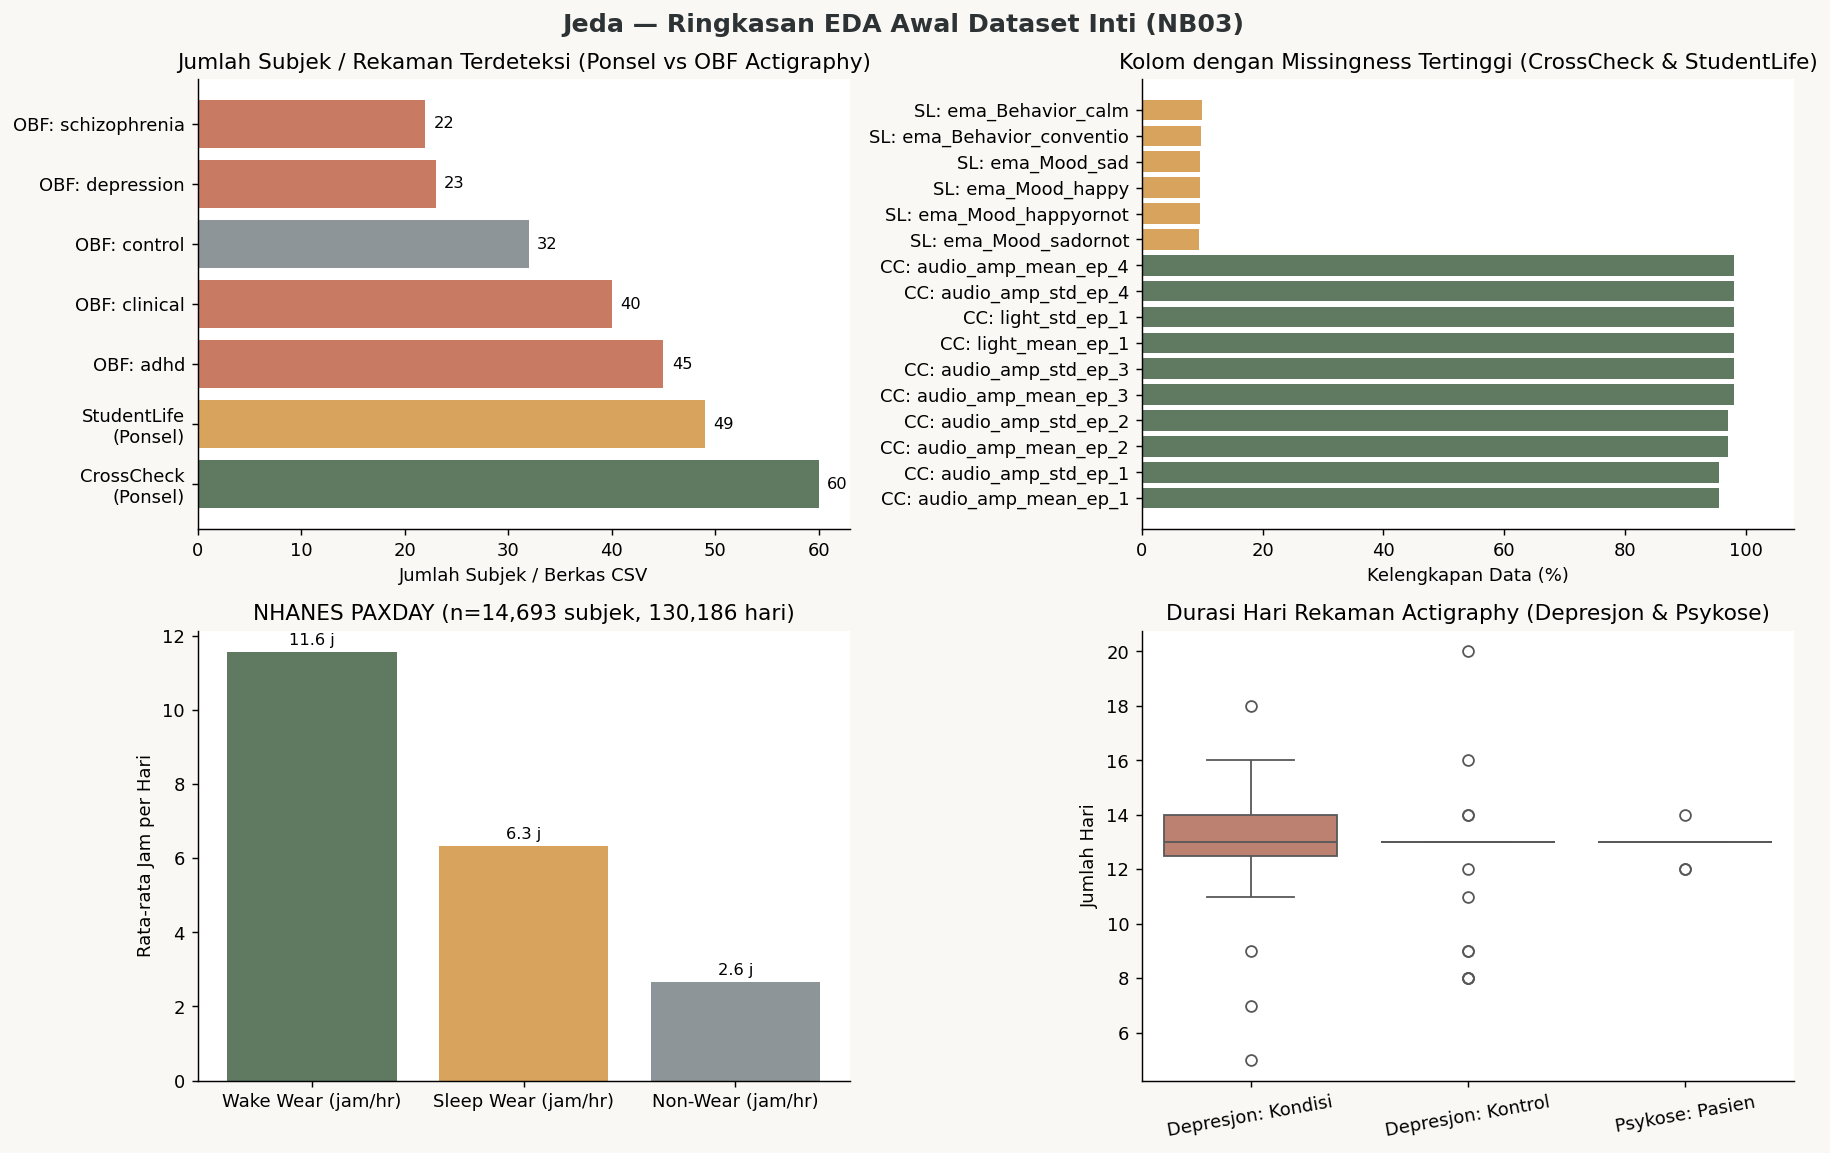

Grafik EDA disimpan ke: ./artifacts\figures\nb03_eda_overview.png


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

palette = CONFIG["ui_palette"]
plt.rcParams["axes.facecolor"] = "#FFFFFF"
plt.rcParams["figure.facecolor"] = palette["background"]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=130)
fig.suptitle("Jeda: Ringkasan EDA Awal Dataset Inti (NB03)", fontsize=14, fontweight="bold", color=palette["text_primary"])

# Panel 1: Jumlah subjek per dataset & kelompok
ax = axes[0, 0]
counts_labels, counts_vals, counts_colors = [], [], []
if "crosscheck_cleaned" in schema_summary:
    counts_labels.append("CrossCheck\n(Ponsel)")
    counts_vals.append(schema_summary["crosscheck_cleaned"]["unique_subjects"] or 0)
    counts_colors.append(palette["stable"])
if "studentlife_cleaned" in schema_summary:
    counts_labels.append("StudentLife\n(Ponsel)")
    counts_vals.append(schema_summary["studentlife_cleaned"]["unique_subjects"] or 0)
    counts_colors.append(palette["shifting"])
for grp, cnt in sorted(obf_info.get("group_counts", {}).items()):
    counts_labels.append(f"OBF: {grp}")
    counts_vals.append(cnt)
    counts_colors.append(palette["attention"] if grp != "control" else palette["abstain"])

ax.barh(counts_labels, counts_vals, color=counts_colors)
ax.set_title("Jumlah Subjek / Rekaman Terdeteksi (Ponsel vs OBF Actigraphy)")
ax.set_xlabel("Jumlah Subjek / Berkas CSV")
for i, v in enumerate(counts_vals):
    ax.text(v + 0.8, i, str(v), va="center", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

# Panel 2: Tingkat kelengkapan (non-null %) fitur CrossCheck & StudentLife
ax = axes[0, 1]
completeness_items = []
if not df_cc.empty:
    for col, val in (1.0 - df_cc.isna().mean()).sort_values(ascending=True).head(10).items():
        completeness_items.append((f"CC: {col[:22]}", val * 100.0, palette["stable"]))
if not df_sl.empty:
    for col, val in (1.0 - df_sl.isna().mean()).sort_values(ascending=True).head(6).items():
        completeness_items.append((f"SL: {col[:22]}", val * 100.0, palette["shifting"]))

if completeness_items:
    labels_c, vals_c, cols_c = zip(*completeness_items)
    ax.barh(labels_c, vals_c, color=cols_c)
    ax.set_xlim(0, 108)
    ax.set_xlabel("Kelengkapan Data (%)")
    ax.set_title("Kolom dengan Missingness Tertinggi (CrossCheck & StudentLife)")
ax.spines[["top", "right"]].set_visible(False)

# Panel 3: NHANES PAXDAY Wear vs Sleep vs Non-wear (khusus wrist-actigraphy)
ax = axes[1, 0]
if not df_paxday.empty:
    wear_cols = [c for c in ["PAXWWMD", "PAXSWMD", "PAXNWMD"] if c in df_paxday.columns]
    if wear_cols:
        sample_pax = df_paxday[wear_cols].dropna().sample(min(5000, len(df_paxday)), random_state=CONFIG["project"]["seed"])
        means_hrs = sample_pax.mean() / 60.0
        ax.bar(
            ["Wake Wear (jam/hr)", "Sleep Wear (jam/hr)", "Non-Wear (jam/hr)"][:len(means_hrs)],
            means_hrs.values,
            color=[palette["stable"], palette["shifting"], palette["abstain"]][:len(means_hrs)],
        )
        ax.set_ylabel("Rata-rata Jam per Hari")
        ax.set_title(f"NHANES PAXDAY (n={df_paxday['SEQN'].nunique():,} subjek, {len(df_paxday):,} hari)")
        for i, v in enumerate(means_hrs.values):
            ax.text(i, v + 0.2, f"{v:.1f} j", ha="center", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)

# Panel 4: Distribusi hari rekaman Depresjon & Psykose
ax = axes[1, 1]
dep_scores_candidates = list(dep_dir.rglob("scores.csv"))
psy_info_path = psy_dir / "patients_info.csv"
days_plot_data = []
if dep_scores_candidates:
    df_dep_sc = pd.read_csv(dep_scores_candidates[0])
    if "days" in df_dep_sc.columns:
        grp_lbl = df_dep_sc["number"].astype(str).str.startswith("condition").map({True: "Depresjon: Kondisi", False: "Depresjon: Kontrol"})
        for g_name, sub in df_dep_sc.groupby(grp_lbl):
            days_plot_data.append(pd.DataFrame({"kelompok": g_name, "days": sub["days"].dropna()}))
if psy_info_path.exists():
    df_psy_inf = pd.read_csv(psy_info_path)
    if "days" in df_psy_inf.columns:
        days_plot_data.append(pd.DataFrame({"kelompok": "Psykose: Pasien", "days": df_psy_inf["days"].dropna()}))

if days_plot_data:
    df_days_all = pd.concat(days_plot_data, ignore_index=True)
    sns.boxplot(
        data=df_days_all,
        x="kelompok",
        y="days",
        hue="kelompok",
        palette=[palette["attention"], palette["abstain"], palette["shifting"]][:df_days_all["kelompok"].nunique()],
        legend=False,
        ax=ax,
    )
    ax.set_title("Durasi Hari Rekaman Actigraphy (Depresjon & Psykose)")
    ax.set_xlabel("")
    ax.set_ylabel("Jumlah Hari")
    ax.tick_params(axis="x", rotation=10)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig_path = FIGURES_DIR / "nb03_eda_overview.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Grafik EDA disimpan ke: {fig_path}")


Grafik `nb03_eda_overview.png` merangkum kondisi mentah seluruh sumber dalam 4 panel:
1. **Panel kiri atas (`Jumlah Subjek / Rekaman Terdeteksi (Ponsel vs OBF Actigraphy)`)**: CrossCheck (`60` subjek / `5.853` hari) dan StudentLife (`49` subjek / `1.912` hari) menjadi tulang punggung pemodelan longitudinal ponsel, sedangkan OBF memberi kelompok klinis terpisah (`adhd`, `clinical`, `control`, `depression`, `schizophrenia`).
2. **Panel kanan atas (`Kolom dengan Missingness Tertinggi (CrossCheck & StudentLife)`)**: terlihat sejumlah fitur turunannya banyak bernilai kosong, sehingga kita wajib memvalidasi mana kolom yang rusak dan mana yang memang sengaja bernilai `0` atau kosong saat sensor mati.
3. **Panel kiri bawah (`NHANES PAXDAY (n=14,693 subjek, 130,186 hari)`)**: populasi umum tersebar merata lintas usia dan durasi hari, ideal untuk **Kurva Sehat** setelah hari tak valid disaring.
4. **Panel kanan bawah (`Durasi Hari Rekaman Actigraphy (Depresjon & Psykose)`)**: panjang hari rekaman Depresjon dan Psykose tampak mirip pola kelompoknya dengan sebagian OBF, memperkuat kecurigaan perlunya audit duplikasi subjek.

### Langkah Berikutnya: Notebook 04: Validasi Integritas dan Kualitas Data (*Data Validation*)

Notebook 03 baru membuktikan bahwa file data terbaca dan muat di 8 GB RAM, namun memunculkan **3 risiko kritis** yang wajib diaudit sebelum kita memilih sampel atau melatih model:
1. **Risiko kebocoran subjek lintas folder klinis**: Apakah `Depresjon` dan `Psykose` sebenarnya berisi subjek yang sama dengan bagian `depression` dan `schizophrenia` di `OBF-Psychiatric`? Jika digabung begitu saja, evaluasi model referensi kita akan tercemar duplikasi.
2. **Risiko artefak sensor mati (*sensor-off*) pada data ponsel**: Saat sensor ponsel mati berjam-jam, apakah skor gejala EMA ikut turun/naik secara semu, dan apakah di StudentLife terdapat angka durasi tidur negatif yang mustahil secara fisik?
3. **Risiko kode nilai bawaan SAS (`0`) & jam pakai tidak memadai di NHANES**: Pada file `.xpt` NHANES, nilai waktu pakai rendah atau nol bisa mendistorsi kurva persentil aktivitas sehat.

Di **Notebook 04 (`04_data_validation.ipynb`)**, kita melakukan audit forensik untuk menjawab ketiga risiko ini secara kuantitatif.